## 1. Configuracion e inventario

### 1.1 Conectar Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.2 Rutas y respaldo

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm import tqdm

RUTA_BASE = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos'
RUTA_TRAIN = os.path.join(RUTA_BASE, 'Train')
RUTA_TEST = os.path.join(RUTA_BASE, 'Test')

# Salidas en tu propio Drive (carpetas nuevas)
SALIDA_TRAIN = '/content/drive/MyDrive/VGG16_rostros/train'
SALIDA_TEST = '/content/drive/MyDrive/VGG16_rostros/test'

clases = ['Redondo', 'Rectangular', 'Ovalado', 'Cuadrado']
extensiones = ('.jpg', '.jpeg', '.png')
TAM = 224

### 1.3 Instalar Dlib

In [ ]:
!pip install dlib -q

### 1.4 Detector de rostros y vista previa

Las fotos traen fondo, torso y encuadres muy distintos. Para que la red mire la forma de la cara y no lo que la rodea, primero se localiza el rostro con el detector frontal de `dlib` y se recorta.

Cómo se arma el recorte:
- Si la foto tiene varios rostros, se queda con el más grande.
- Se agrega un margen alrededor de la caja del rostro: 15% a cada lado, 50% hacia arriba (para que entre la frente completa) y 15% hacia abajo (para que entre el mentón).
- El resultado se ajusta a 224×224, el tamaño que pide VGG-16. Se rellena con gris para no estirar ni deformar la cara, porque deformarla cambiaría justo la forma que queremos clasificar.

La celda de abajo prueba el recorte con una foto al azar de cada clase: arriba la original y abajo el recorte. Sirve para revisar a simple vista que la frente y el mentón queden dentro. Como la foto se elige al azar, conviene correrla varias veces.

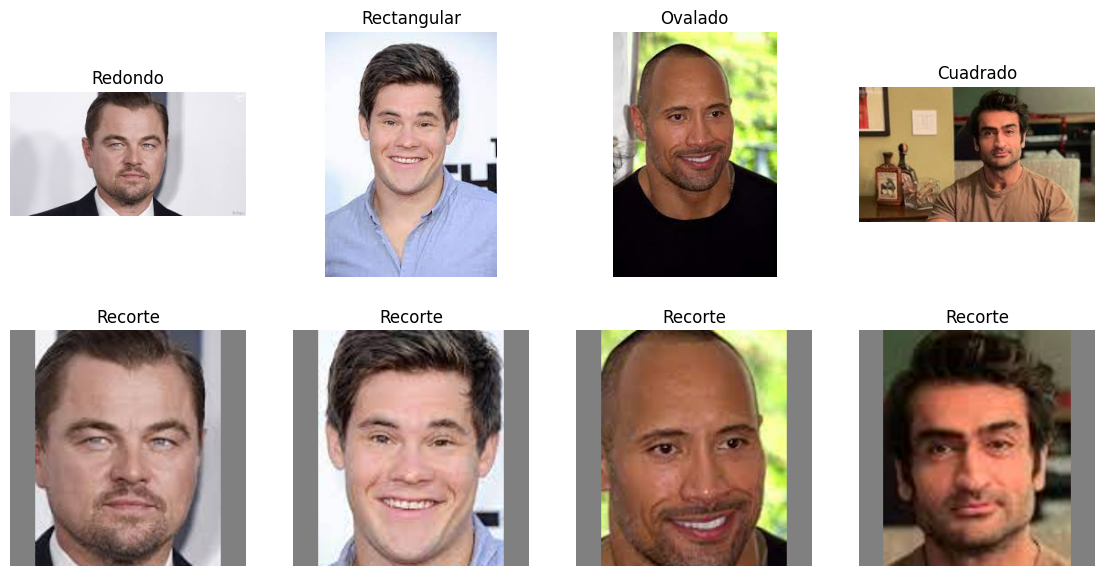

In [ ]:
import dlib

detector = dlib.get_frontal_face_detector()

def ampliar_caja(r, ancho_img, alto_img):
    ancho = r.right() - r.left()
    alto = r.bottom() - r.top()
    x1 = max(0, int(r.left() - 0.15 * ancho))
    x2 = min(ancho_img, int(r.right() + 0.15 * ancho))
    y1 = max(0, int(r.top() - 0.5 * alto))
    y2 = min(alto_img, int(r.bottom() + 0.15 * alto))
    return x1, y1, x2, y2

def recortar_rostro(imagen):
    """Devuelve la cara recortada en TAM x TAM, o None si no hay rostro."""
    arreglo = np.array(imagen)
    rostros = detector(arreglo, 1)
    if len(rostros) == 0:
        return None
    r = max(rostros, key=lambda c: c.area())   # el rostro más grande
    x1, y1, x2, y2 = ampliar_caja(r, imagen.width, imagen.height)
    cara = imagen.crop((x1, y1, x2, y2))
    return ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128))

# Vista previa: una imagen por clase
plt.figure(figsize=(14, 7))
for i, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_TRAIN, nombre)
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]
    f = random.choice(archivos)
    imagen = Image.open(os.path.join(carpeta, f)).convert('RGB')
    cara = recortar_rostro(imagen)

    plt.subplot(2, 4, i + 1)
    plt.imshow(imagen)
    plt.title(nombre)
    plt.axis('off')

    plt.subplot(2, 4, i + 5)
    if cara is not None:
        plt.imshow(cara)
        plt.title('Recorte')
    else:
        plt.title('Sin rostro')
    plt.axis('off')
plt.show()

### 1.5 Recortar Train y Test

Se aplica el mismo recorte a todas las fotos. Cada imagen recortada se guarda como `.jpg` con el mismo nombre de la original, dentro de carpetas nuevas en tu Drive, sin tocar el conjunto de datos compartido.


In [ ]:
def recortar_conjunto(ruta_origen, ruta_salida, nombre_conjunto):
    sin_rostro = {}
    guardadas = {}
    for nombre in clases:
        os.makedirs(os.path.join(ruta_salida, nombre), exist_ok=True)
        sin_rostro[nombre] = []
        guardadas[nombre] = 0
        carpeta = os.path.join(ruta_origen, nombre)
        archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]

        for archivo in tqdm(archivos, desc=f'{nombre_conjunto} {nombre}'):
            try:
                imagen = Image.open(os.path.join(carpeta, archivo)).convert('RGB')
                cara = recortar_rostro(imagen)
                if cara is None:
                    sin_rostro[nombre].append(archivo)
                    continue
                nombre_salida = os.path.splitext(archivo)[0] + '.jpg'
                cara.save(os.path.join(ruta_salida, nombre, nombre_salida))
                guardadas[nombre] += 1
            except Exception:
                sin_rostro[nombre].append(archivo)

    print()
    for nombre in clases:
        print(nombre, ': guardadas', guardadas[nombre],
              '| sin rostro o con error', len(sin_rostro[nombre]))
    return sin_rostro

sin_rostro_train = recortar_conjunto(RUTA_TRAIN, SALIDA_TRAIN, 'Train')
sin_rostro_test = recortar_conjunto(RUTA_TEST, SALIDA_TEST, 'Test')

Train Cuadrado: 100%|██████████| 323/323 [05:39<00:00,  1.05s/it]



Redondo : guardadas 322 | sin rostro o con error 0
Rectangular : guardadas 316 | sin rostro o con error 1
Ovalado : guardadas 318 | sin rostro o con error 1
Cuadrado : guardadas 323 | sin rostro o con error 0


Test Cuadrado: 100%|██████████| 80/80 [02:58<00:00,  2.23s/it]


Redondo : guardadas 83 | sin rostro o con error 0
Rectangular : guardadas 83 | sin rostro o con error 0
Ovalado : guardadas 81 | sin rostro o con error 0
Cuadrado : guardadas 80 | sin rostro o con error 0


## 2. Preparación de los datos

### 2.1 Excluir duplicados y dividir en entrenamiento y validación

Se lee la lista de fotos repetidas o contradictorias y se quitan de Train. Con lo que queda se separa 80% para entrenar y 20% para validar, manteniendo la misma proporción de cada clase. La validación sirve para decidir cuándo parar el entrenamiento y qué versión del modelo guardar. Test no se toca.

In [ ]:
import csv, shutil
from sklearn.model_selection import train_test_split

RUTA_LISTA = '/content/drive/MyDrive/VGG16_rostros/lista_exclusion.csv'
with open(RUTA_LISTA, encoding='utf-8') as fh:
    excluir = {(fila['clase'], fila['nombre']) for fila in csv.DictReader(fh)}
print('Fotos en la lista de exclusión:', len(excluir))

rutas, etiquetas = [], []
for nombre in clases:
    carpeta = os.path.join(SALIDA_TRAIN, nombre)
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(extensiones) and (nombre, os.path.splitext(archivo)[0]) not in excluir:
            rutas.append(os.path.join(carpeta, archivo))
            etiquetas.append(nombre)
print('Train limpio:', len(rutas), '(esperado 1186)')

rutas_train, rutas_val, et_train, et_val = train_test_split(
    rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=42)
print('Entrenamiento:', len(rutas_train), '| Validación:', len(rutas_val))

Fotos en la lista de exclusión: 92
Train limpio: 1186 (esperado 1186)
Entrenamiento: 948 | Validación: 238


### 2.2 Copiar los tres conjuntos al disco local de Colab

Keras toma la etiqueta de cada foto del nombre de su carpeta, así que se arma la estructura `train/`, `val/` y `test/`, cada una con una carpeta por clase. Se copia al disco local de Colab porque leer desde Drive en cada época es mucho más lento.

In [ ]:
RUTA_SPLIT = '/content/dataset_split'
if os.path.exists(RUTA_SPLIT):
    shutil.rmtree(RUTA_SPLIT)

def copiar(lista_rutas, lista_etiquetas, subcarpeta):
    for ruta, etiqueta in zip(lista_rutas, lista_etiquetas):
        destino = os.path.join(RUTA_SPLIT, subcarpeta, etiqueta)
        os.makedirs(destino, exist_ok=True)
        shutil.copy(ruta, destino)

copiar(rutas_train, et_train, 'train')
copiar(rutas_val, et_val, 'val')

for nombre in clases:
    origen = os.path.join(SALIDA_TEST, nombre)
    destino = os.path.join(RUTA_SPLIT, 'test', nombre)
    os.makedirs(destino, exist_ok=True)
    for archivo in os.listdir(origen):
        shutil.copy(os.path.join(origen, archivo), destino)

for sub in ['train', 'val', 'test']:
    print(sub, {n: len(os.listdir(os.path.join(RUTA_SPLIT, sub, n))) for n in clases})

train {'Redondo': 224, 'Rectangular': 244, 'Ovalado': 240, 'Cuadrado': 240}
val {'Redondo': 56, 'Rectangular': 62, 'Ovalado': 60, 'Cuadrado': 60}
test {'Redondo': 83, 'Rectangular': 83, 'Ovalado': 81, 'Cuadrado': 80}


### 2.3 Cargar los datos en Keras y aumento de datos

`image_dataset_from_directory` lee las carpetas y entrega las fotos de 224×224 con su etiqueta, en lotes de 32. Si Colab se queda sin memoria, se baja el lote a 16.

Found 948 files belonging to 4 classes.
Found 238 files belonging to 4 classes.
Found 327 files belonging to 4 classes.


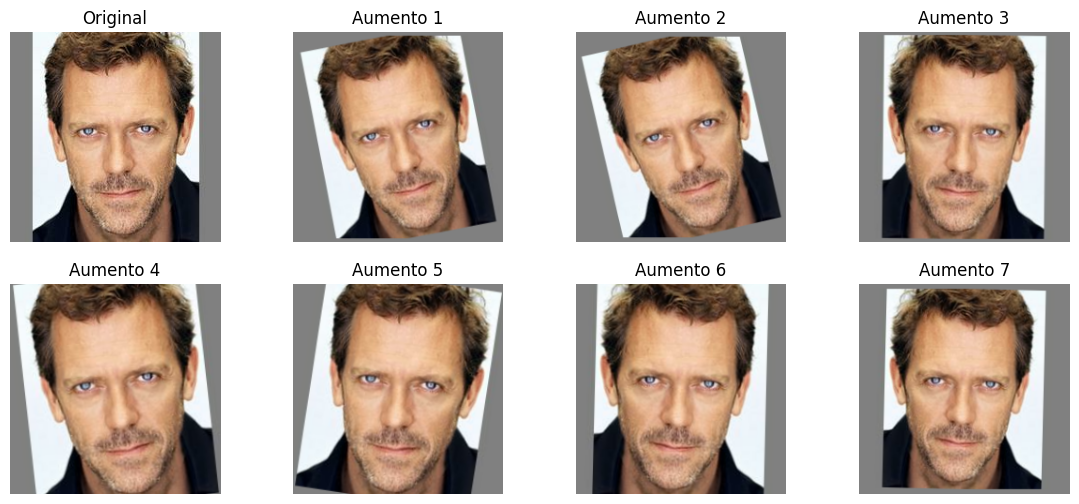

In [ ]:
import tensorflow as tf

TAM_IMG = (224, 224)
LOTE = 32

datos_train = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'train'), label_mode='categorical', class_names=clases,
    image_size=TAM_IMG, batch_size=LOTE, shuffle=True, seed=42)
datos_val = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'val'), label_mode='categorical', class_names=clases,
    image_size=TAM_IMG, batch_size=LOTE, shuffle=False)
datos_test = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'test'), label_mode='categorical', class_names=clases,
    image_size=TAM_IMG, batch_size=LOTE, shuffle=False)

aumento = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.04, fill_mode='constant', fill_value=128),
    tf.keras.layers.RandomZoom(0.1, fill_mode='constant', fill_value=128)])

for imagenes, _ in datos_train.take(1):
    imagen = imagenes[0]
plt.figure(figsize=(14, 6))
plt.subplot(2, 4, 1)
plt.imshow(imagen.numpy().astype('uint8')); plt.title('Original'); plt.axis('off')
for i in range(7):
    modificada = aumento(tf.expand_dims(imagen, 0), training=True)
    plt.subplot(2, 4, i + 2)
    plt.imshow(modificada[0].numpy().astype('uint8')); plt.title(f'Aumento {i + 1}'); plt.axis('off')
plt.show()

## 3. Modelo base (VGG-16 congelada)

### 3.1 Cargar VGG-16 preentrenada

Se carga VGG-16 con los pesos de ImageNet, sin su capa final de 1000 categorías (`include_top=False`), y se congela: sus pesos no cambian al entrenar. Así solo se aprende la parte nueva.

### 3.2 Armar el modelo completo

Cadena de capas:
- entrada →
- aumento de datos (solo al entrenar) →
- `preprocess_input` (el preprocesamiento propio de VGG-16 para los píxeles) →
- VGG-16 congelada →
- promedio global (resume cada mapa de características en un número) →
- Dropout 30% (apaga conexiones al azar para evitar memorización) →
- capa final de 4 salidas con softmax (una probabilidad por clase).

Se prefiere el promedio global a aplanar todo porque con ~950 imágenes un modelo con demasiados parámetros memoriza en vez de aprender.

In [ ]:
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

base = tf.keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base.trainable = False
print('Capas de VGG-16:', len(base.layers), '| salida:', base.output_shape)

entrada = tf.keras.Input(shape=(224, 224, 3))
x = aumento(entrada)
x = tf.keras.applications.vgg16.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
salida = tf.keras.layers.Dense(4, activation='softmax')(x)

modelo = tf.keras.Model(entrada, salida)
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy'])

modelo.summary()

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Capas de VGG-16: 19 | salida: (None, 7, 7, 512)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │      2,052 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,716,740 (56.14 MB)

 Trainable params: 2,052 (8.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 4. Entrenamiento del modelo base

### 4.1 Entrenamiento



In [ ]:
tf.keras.utils.set_random_seed(42)

RUTA_MODELO = '/content/drive/MyDrive/VGG16_rostros/vgg16_base.keras'

guardar_mejor = tf.keras.callbacks.ModelCheckpoint(
    RUTA_MODELO, monitor='val_accuracy', save_best_only=True, verbose=1)
parar_temprano = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=5, restore_best_weights=True)

historial = modelo.fit(
    datos_train, validation_data=datos_val, epochs=25,
    callbacks=[guardar_mejor, parar_temprano])

Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.2362 - loss: 3.5010
Epoch 1: val_accuracy improved from None to 0.26050, saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_base.keras

Epoch 1: finished saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_base.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 493ms/step - accuracy: 0.2321 - loss: 3.2243 - val_accuracy: 0.2605 - val_loss: 2.1691
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.3187 - loss: 2.5244
Epoch 2: val_accuracy improved from 0.26050 to 0.29832, saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_base.keras

Epoch 2: finished saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_base.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 169ms/step - accuracy: 0.3006 - loss: 2.5142 - val_accuracy: 0.2983 - val_loss: 1.7907
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.2856 - loss: 2.4592
Epoch 3: val_accuracy improved from 0.29832 to 0.38235, saving model to /content

### 4.2 Curvas de entrenamiento

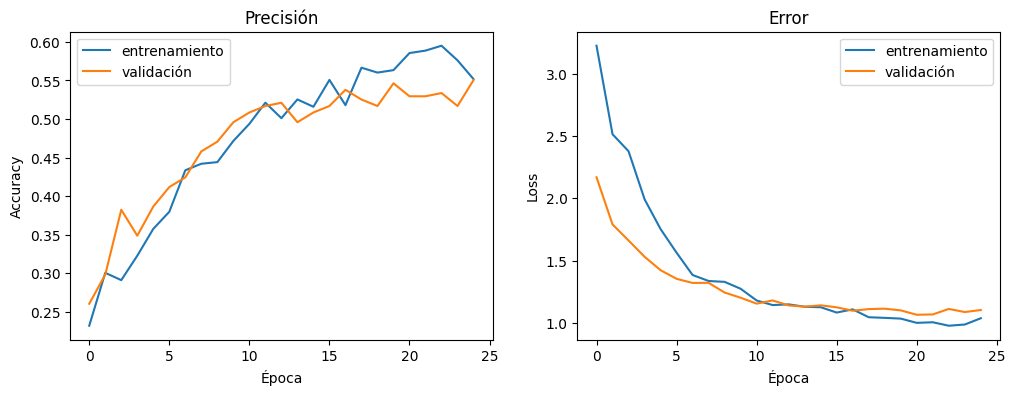

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='entrenamiento')
plt.plot(historial.history['val_accuracy'], label='validación')
plt.xlabel('Época'); plt.ylabel('Accuracy'); plt.title('Precisión'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='entrenamiento')
plt.plot(historial.history['val_loss'], label='validación')
plt.xlabel('Época'); plt.ylabel('Loss'); plt.title('Error'); plt.legend()
plt.show()

### 4.3 Evaluación del modelo base en Test



Imágenes evaluadas: 327
Accuracy en Test: 0.4404
F1 macro en Test: 0.4115
              precision    recall  f1-score   support

     Redondo      0.487     0.229     0.311        83
 Rectangular      0.371     0.759     0.498        83
     Ovalado      0.516     0.198     0.286        81
    Cuadrado      0.529     0.575     0.551        80

    accuracy                          0.440       327
   macro avg      0.476     0.440     0.412       327
weighted avg      0.475     0.440     0.411       327



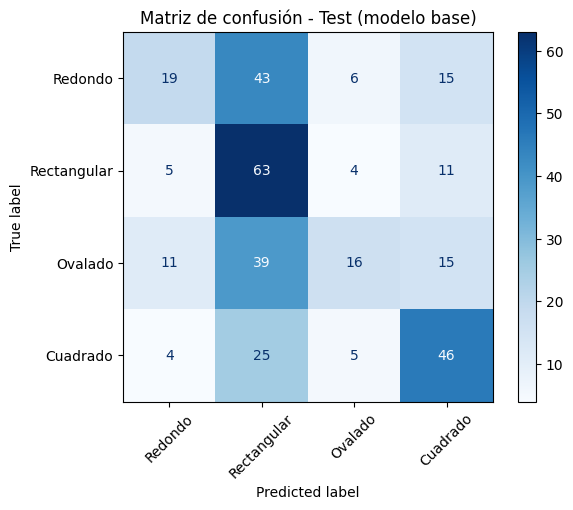

In [ ]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)

y_real = np.concatenate([np.argmax(e.numpy(), axis=1) for _, e in datos_test])
y_pred = np.argmax(modelo.predict(datos_test, verbose=0), axis=1)

print('Imágenes evaluadas:', len(y_real))
print('Accuracy en Test:', round(accuracy_score(y_real, y_pred), 4))
print('F1 macro en Test:', round(f1_score(y_real, y_pred, average='macro'), 4))
print(classification_report(y_real, y_pred, target_names=clases, digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred), display_labels=clases).plot(
    cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusión - Test (modelo base)')
plt.show()

## 5. Fine-tuning (descongelar el último bloque)

### 5.1 Descongelar el último bloque convolucional

Se descongela solo el quinto bloque de VGG-16 (`block5`), que detecta los rasgos más específicos. Los cuatro primeros bloques siguen congelados: detectan bordes y texturas que sirven para cualquier imagen. Se reduce la tasa de aprendizaje a 0.00001 para ajustar sin destruir lo que ya sabe la red.

In [ ]:
y_pred_base = y_pred.copy()   # guarda las predicciones del modelo base para comparar luego

base.trainable = True
for capa in base.layers:
    capa.trainable = capa.name.startswith('block5')

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy', metrics=['accuracy'])

entrenables = sum(int(np.prod(w.shape)) for w in modelo.trainable_weights)
print('Parámetros entrenables ahora:', entrenables)

Parámetros entrenables ahora: 7081476


### 5.2 Entrenamiento con fine-tuning

Mismo esquema que el modelo base, con hasta 30 épocas, paciencia de 6 y otro archivo de guardado para conservar las dos versiones.

In [ ]:
RUTA_MODELO_FT = '/content/drive/MyDrive/VGG16_rostros/vgg16_finetuning.keras'

historial_ft = modelo.fit(
    datos_train, validation_data=datos_val, epochs=30,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(RUTA_MODELO_FT, monitor='val_accuracy',
                                           save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=6,
                                         restore_best_weights=True)])

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.5977 - loss: 0.9715
Epoch 1: val_accuracy improved from None to 0.57143, saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_finetuning.keras

Epoch 1: finished saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_finetuning.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 607ms/step - accuracy: 0.6108 - loss: 0.9538 - val_accuracy: 0.5714 - val_loss: 0.9884
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.6621 - loss: 0.7986
Epoch 2: val_accuracy improved from 0.57143 to 0.58824, saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_finetuning.keras

Epoch 2: finished saving model to /content/drive/MyDrive/VGG16_rostros/vgg16_finetuning.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 238ms/step - accuracy: 0.6698 - loss: 0.7946 - val_accuracy: 0.5882 - val_loss: 0.9343
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.6910 - loss: 0.7891
Epoch 3: val_accuracy improved from 0.58824 to 0.61345, 

### 5.3 Curvas y evaluación en Test del modelo con fine-tuning

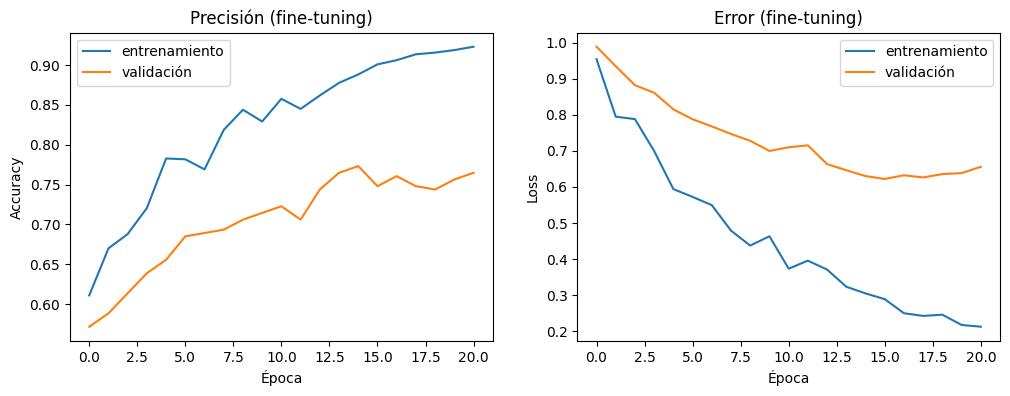

Accuracy en Test: 0.5535
F1 macro en Test: 0.5542
              precision    recall  f1-score   support

     Redondo      0.672     0.542     0.600        83
 Rectangular      0.432     0.723     0.541        83
     Ovalado      0.508     0.370     0.429        81
    Cuadrado      0.742     0.575     0.648        80

    accuracy                          0.554       327
   macro avg      0.588     0.553     0.554       327
weighted avg      0.588     0.554     0.554       327



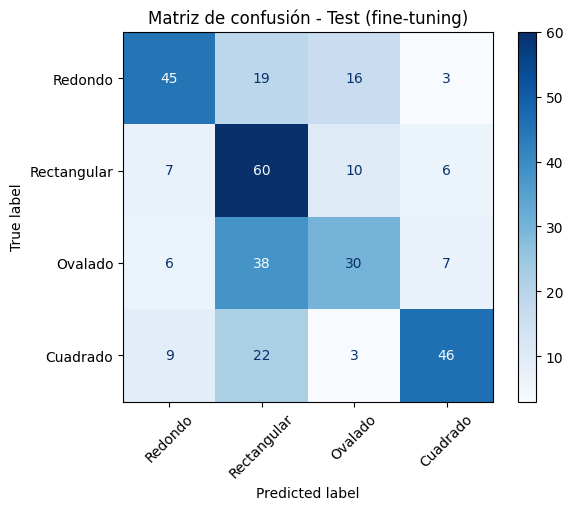

In [ ]:
plt.figure(figsize=(12, 4))
for k, (m, titulo) in enumerate([('accuracy', 'Precisión (fine-tuning)'), ('loss', 'Error (fine-tuning)')]):
    plt.subplot(1, 2, k + 1)
    plt.plot(historial_ft.history[m], label='entrenamiento')
    plt.plot(historial_ft.history['val_' + m], label='validación')
    plt.xlabel('Época'); plt.ylabel(m.capitalize()); plt.title(titulo); plt.legend()
plt.show()

y_pred_ft = np.argmax(modelo.predict(datos_test, verbose=0), axis=1)
print('Accuracy en Test:', round(accuracy_score(y_real, y_pred_ft), 4))
print('F1 macro en Test:', round(f1_score(y_real, y_pred_ft, average='macro'), 4))
print(classification_report(y_real, y_pred_ft, target_names=clases, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred_ft), display_labels=clases).plot(
    cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusión - Test (fine-tuning)')
plt.show()

In [ ]:
import re

with open('/content/drive/MyDrive/VGG16_rostros/test_con_copia_en_train.csv', encoding='utf-8') as fh:
    con_copia = {(f['clase'], f['nombre']) for f in csv.DictReader(fh)}

claves = [(os.path.basename(os.path.dirname(r)), os.path.splitext(os.path.basename(r))[0])
          for r in datos_test.file_paths]
limpio = np.array([k not in con_copia for k in claves])
es_hash = np.array([bool(re.fullmatch(r'[0-9a-f]{32}', n)) for _, n in claves])
print('Test completo:', len(limpio), '| sin copias en Train:', limpio.sum(),
      '| tipo hash:', es_hash.sum(), '| otros:', (~es_hash).sum())

for nombre, pred in [('Base', y_pred_base), ('Fine-tuning', y_pred_ft)]:
    print(f'\n{nombre}')
    for etiqueta, m in [('Test completo', np.ones(len(y_real), bool)), ('Test sin copias', limpio),
                        ('Solo tipo hash', es_hash), ('Solo otros', ~es_hash)]:
        print(f'  {etiqueta:16s} acc {accuracy_score(y_real[m], pred[m]):.3f} | F1 macro {f1_score(y_real[m], pred[m], average="macro"):.3f}')

Test completo: 327 | sin copias en Train: 312 | tipo hash: 250 | otros: 77

Base
  Test completo    acc 0.440 | F1 macro 0.412
  Test sin copias  acc 0.433 | F1 macro 0.391
  Solo tipo hash   acc 0.428 | F1 macro 0.345
  Solo otros       acc 0.481 | F1 macro 0.427

Fine-tuning
  Test completo    acc 0.554 | F1 macro 0.554
  Test sin copias  acc 0.538 | F1 macro 0.537
  Solo tipo hash   acc 0.496 | F1 macro 0.470
  Solo otros       acc 0.740 | F1 macro 0.663


## 6. Comparación de resultados

Todas las cifras de Test provienen de las evaluaciones de las secciones 4.3 y 5.3 (327 imágenes). La comparación entre modelos se hace solo en Test: la validación de los demás modelos se dividió sin quitar antes los duplicados y no es comparable.

| Modelo | Mejor precisión en validación | Accuracy en Test | F1 macro en Test |
|---|---|---|---|
| VGG-16 base | ~54% | 42.8% | 0.410 |
| VGG-16 con fine-tuning | ~76% | 51.7% | 0.526 |
| Inception V3 base | 60.9% | 37.6% | 0.366 |
| Inception V3 con fine-tuning | 80.5% | 55.7% | 0.554 |

| Clase | Recall VGG-16 fine-tuning | Recall Inception fine-tuning |
|---|---|---|
| Redondo | 48.2% | 51.8% |
| Rectangular | 59.0% | 71.1% |
| Ovalado | 42.0% | 50.6% |
| Cuadrado | 57.5% | 48.7% |

**Lectura.** Con 327 imágenes, el margen de error de un accuracy de ~50% es de ±5 puntos, así que la diferencia entre VGG-16 e Inception con fine-tuning (4 puntos) no es concluyente. Los modelos de los compañeros se entrenaron con algunas fotos de Test repetidas en Train. Al quitar esas 15 fotos, VGG-16 con fine-tuning baja de 51.7% a 49.7% de accuracy.

**Cambio de distribución.** En las fotos de Test cuyo nombre es de otro estilo (77 fotos) el modelo acierta 76.6%, igual que en validación; en las de estilo hash (250 fotos) acierta 44.0%. Indica que el origen de las imágenes pesa más que la forma del rostro. Es un indicio, no una prueba: ese subconjunto es pequeño y tiene otra mezcla de clases.

In [ ]:
y_val = np.concatenate([np.argmax(e.numpy(), axis=1) for _, e in datos_val])
p_val = np.argmax(modelo.predict(datos_val, verbose=0), axis=1)
hash_val = np.array([bool(re.fullmatch(r'[0-9a-f]{32}', os.path.splitext(os.path.basename(r))[0])) for r in datos_val.file_paths])
print('Validación tipo hash:', hash_val.sum(), 'fotos | acc', round(accuracy_score(y_val[hash_val], p_val[hash_val]), 3))
print('Validación otros:', (~hash_val).sum(), 'fotos | acc', round(accuracy_score(y_val[~hash_val], p_val[~hash_val]), 3))

Validación tipo hash: 47 fotos | acc 0.745
Validación otros: 191 fotos | acc 0.78


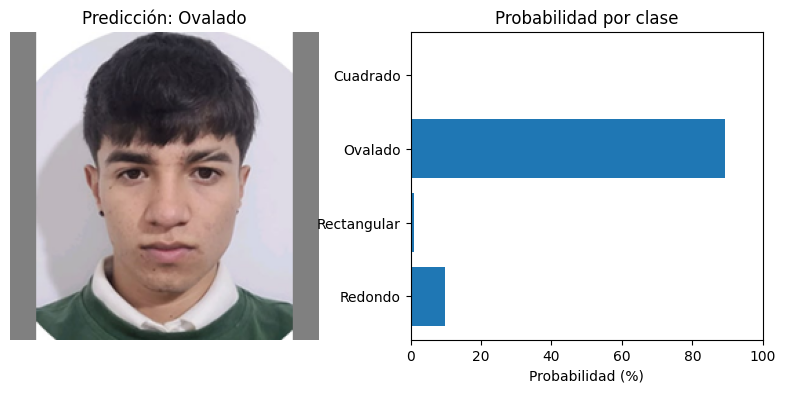

In [ ]:
def predecir_rostro(ruta_foto):
    imagen = Image.open(ruta_foto).convert('RGB')
    cara = recortar_rostro(imagen)           # el mismo recorte del entrenamiento
    if cara is None:
        print('No se detectó ningún rostro en la foto')
        return
    entrada = np.expand_dims(np.array(cara), axis=0).astype('float32')
    probabilidades = modelo.predict(entrada, verbose=0)[0]
    mejor = int(np.argmax(probabilidades))

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cara); plt.title('Predicción: ' + clases[mejor]); plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.barh(clases, probabilidades * 100); plt.xlim(0, 100)
    plt.xlabel('Probabilidad (%)'); plt.title('Probabilidad por clase')
    plt.show()

predecir_rostro('/content/drive/MyDrive/VGG16_rostros/mi_foto2.jpg')   # ajusta a tu foto